# Numerische FEM-Lösung und Konvergenzanalyse

Behandlung des Randwertproblems:
$$\begin{cases} -u''(x) = (1 - 10x^2)e^{-5x^2} & \text{für } x \in (-1, 1) \\ u(-1) = u(1) = 0 \end{cases}$$

Analytische Lösung:
$$u(x) = \frac{1}{10}\left(e^{-5x^2} - e^{-5}\right)$$

In [5]:
import numpy as np
from scipy import integrate
from scipy.sparse import diags
from scipy.sparse.linalg import spsolve
import matplotlib.pyplot as plt

Anzahl innere Knoten N: 9
Knoten x_i:        [-1.  -0.8 -0.6 -0.4 -0.2 -0.   0.2  0.4  0.6  0.8  1. ]
FEM-Lösung u_h:    [0.       0.003402 0.015856 0.044259 0.081199 0.099326 0.081199 0.044259
 0.015856 0.003402 0.      ]
Exakte Lösung u:   [0.       0.003402 0.015856 0.044259 0.081199 0.099326 0.081199 0.044259
 0.015856 0.003402 0.      ]


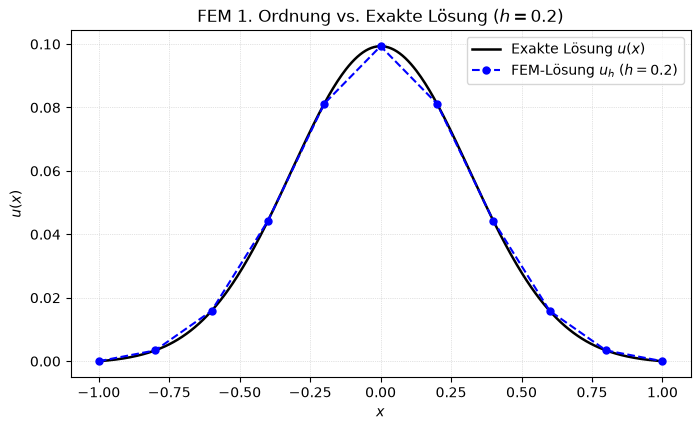

In [6]:
# AUFGABE 4

# Parameter & Diskretisierung
h = 0.2
nodes = np.arange(-1.0, 1.0 + h/2.0, h)   # 11 Knoten: -1.0 bis 1.0
N = len(nodes) - 2                      # 9 innere Freiheitsgrade
x_inner = nodes[1:-1]

# 1. Steifigkeitsmatrix A_h (tridiagonal)
main_diag = (2.0 / h) * np.ones(N)
off_diag  = (-1.0 / h) * np.ones(N - 1)
A = np.diag(main_diag) + np.diag(off_diag, -1) + np.diag(off_diag, 1)

# 2. Rechte Seite f(x) & Lastvektor b_h via numerischer Quadratur
def f(x):
    return (1.0 - 10.0 * x**2) * np.exp(-5.0 * x**2)

b = np.zeros(N)
for idx, i in enumerate(range(1, N + 1)):
    x_im1 = nodes[i - 1]
    x_i   = nodes[i]
    x_ip1 = nodes[i + 1]

    # Lineare Hutfunktionen phi_i(x)
    val_left, _  = integrate.quad(lambda x: f(x) * (x - x_im1) / h, x_im1, x_i)
    val_right, _ = integrate.quad(lambda x: f(x) * (x_ip1 - x) / h, x_i, x_ip1)
    b[idx] = val_left + val_right

# 3. LGS lösen und Randwerte u(-1) = u(1) = 0 anhängen
u_inner = np.linalg.solve(A, b)
u_fem = np.concatenate(([0.0], u_inner, [0.0]))

# 4. Analytische Lösung zum Vergleich
def u_exact(x):
    return 0.1 * (np.exp(-5.0 * x**2) - np.exp(-5.0))

# Ausgabe & Visualisierung
print(f"Anzahl innere Knoten N: {N}")
print("Knoten x_i:       ", np.round(nodes, 2))
print("FEM-Lösung u_h:   ", np.round(u_fem, 6))
print("Exakte Lösung u:  ", np.round(u_exact(nodes), 6))

x_fine = np.linspace(-1.0, 1.0, 400)
plt.figure(figsize=(8, 4.5))
plt.plot(x_fine, u_exact(x_fine), 'k-', label='Exakte Lösung $u(x)$', lw=1.8)
plt.plot(nodes, u_fem, 'bo--', label=f'FEM-Lösung $u_h$ ($h={h}$)', ms=5)
plt.title(f'FEM 1. Ordnung vs. Exakte Lösung ($h={h}$)')
plt.xlabel('$x$')
plt.ylabel('$u(x)$')
plt.grid(True, linestyle=':', alpha=0.7)
plt.legend()
plt.show()


h          | L2-Fehler      | EOC (L2)   | Max-Fehler     | EOC (Max) 
-----------------------------------------------------------------
2.0e-01    | 2.315741e-03   | -          | 4.186405e-03   | -         
2.0e-02    | 2.365749e-05   | 1.99       | 4.991256e-05   | 1.92      
2.0e-03    | 2.366257e-07   | 2.00       | 4.999912e-07   | 2.00      


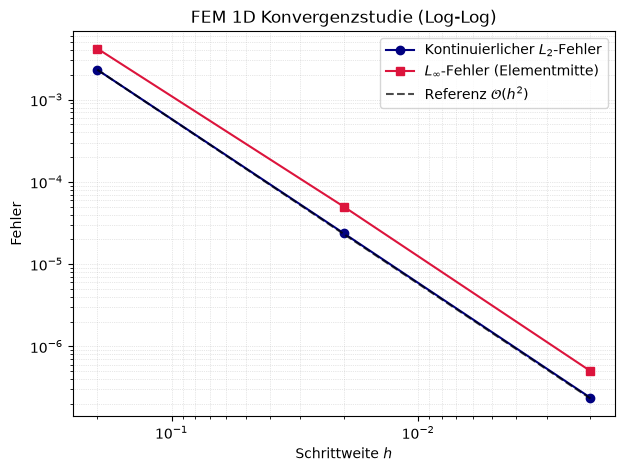

In [8]:
# AUFGABE 5

def f(x):
    return (1.0 - 10.0 * x**2) * np.exp(-5.0 * x**2)

def u_exact(x):
    return 0.1 * (np.exp(-5.0 * x**2) - np.exp(-5.0))

def solve_fem_1d(h):
    nodes = np.arange(-1.0, 1.0 + h/2.0, h)
    N = len(nodes) - 2

    # Sparse Steifigkeitsmatrix
    main_diag = (2.0 / h) * np.ones(N)
    off_diag  = (-1.0 / h) * np.ones(N - 1)
    A = diags([off_diag, main_diag, off_diag], [-1, 0, 1], format='csr')

    # Lastvektor via numerischer Quadratur
    b = np.zeros(N)
    for idx, i in enumerate(range(1, N + 1)):
        x_im1 = nodes[i - 1]
        x_i   = nodes[i]
        x_ip1 = nodes[i + 1]
        val_l, _ = integrate.quad(lambda x: f(x) * (x - x_im1) / h, x_im1, x_i)
        val_r, _ = integrate.quad(lambda x: f(x) * (x_ip1 - x) / h, x_i, x_ip1)
        b[idx] = val_l + val_r

    u_inner = spsolve(A, b)
    u_h = np.concatenate(([0.0], u_inner, [0.0]))
    return nodes, u_h

# Kontinuierliche L2- und L_inf-Fehlerberechnung über Element-Teilintervalle
def compute_element_errors(nodes, u_h):
    h_elem = nodes[1] - nodes[0]
    l2_sq_total = 0.0
    max_err_total = 0.0

    for i in range(len(nodes) - 1):
        x_l, x_r = nodes[i], nodes[i+1]
        u_l, u_r = u_h[i], u_h[i+1]

        # Lineare Interpolante u_h(x) auf [x_l, x_r]
        u_h_local = lambda x: u_l + (u_r - u_l) * (x - x_l) / h_elem
        diff_sq   = lambda x: (u_exact(x) - u_h_local(x))**2

        val_sq, _ = integrate.quad(diff_sq, x_l, x_r)
        l2_sq_total += val_sq

        # Max-Fehler in Intervallmitte abtasten
        x_mid = 0.5 * (x_l + x_r)
        max_err_total = max(max_err_total, abs(u_exact(x_mid) - u_h_local(x_mid)))

    return np.sqrt(l2_sq_total), max_err_total

h_values = [2e-1, 2e-2, 2e-3]
errors_l2 = []
errors_max = []

for h_val in h_values:
    nodes, u_h = solve_fem_1d(h_val)
    err_l2, err_max = compute_element_errors(nodes, u_h)
    errors_l2.append(err_l2)
    errors_max.append(err_max)

# Tabellarische Auswertung inkl. EOC
print(f"{'h':<10} | {'L2-Fehler':<14} | {'EOC (L2)':<10} | {'Max-Fehler':<14} | {'EOC (Max)':<10}")
print("-" * 65)

for k, h_val in enumerate(h_values):
    if k == 0:
        print(f"{h_val:<10.1e} | {errors_l2[k]:<14.6e} | {'-':<10} | {errors_max[k]:<14.6e} | {'-':<10}")
    else:
        eoc_l2  = np.log(errors_l2[k] / errors_l2[k-1])   / np.log(h_values[k] / h_values[k-1])
        eoc_max = np.log(errors_max[k] / errors_max[k-1]) / np.log(h_values[k] / h_values[k-1])
        print(f"{h_val:<10.1e} | {errors_l2[k]:<14.6e} | {eoc_l2:<10.2f} | {errors_max[k]:<14.6e} | {eoc_max:<10.2f}")

# Log-Log Konvergenzplot (r"..." verhindert SyntaxWarnings)
plt.figure(figsize=(7, 5))
plt.loglog(h_values, errors_l2, 'o-', label=r'Kontinuierlicher $L_2$-Fehler', color='navy')
plt.loglog(h_values, errors_max, 's-', label=r'$L_\infty$-Fehler (Elementmitte)', color='crimson')

# Referenzsteigung O(h^2)
h_ref = np.array(h_values)
ref_slope = errors_l2[0] * (h_ref / h_ref[0])**2
plt.loglog(h_ref, ref_slope, 'k--', label=r'Referenz $\mathcal{O}(h^2)$', alpha=0.7)

plt.xlabel(r'Schrittweite $h$')
plt.ylabel('Fehler')
plt.title('FEM 1D Konvergenzstudie (Log-Log)')
plt.grid(True, which='both', linestyle=':', alpha=0.6)
plt.legend()
plt.gca().invert_xaxis()
plt.show()